# 50 — GIN Feature Attribution & Mechanistic Analysis

Deep mechanistic analysis of the Gene Integration Network (GIN): which of the 72 input
features drive per-gene integration decisions, and why?

**Core question**: What information does the GIN use to decide how much each gene should
be integrated across species (alpha), beyond the conservation prior?

**Methods applied** (4 independent attribution approaches for robustness):
1. Weight-path importance (|W2| × |W1| product)
2. Gradient-based attribution (per-gene analytical Jacobian)
3. Integrated gradients (baseline→actual, gold-standard completeness)
4. Feature-group ablation (zero-out groups, measure correction change)

**Plus mechanistic analyses**:
5. Partial dependence plots for top features
6. Hidden neuron analysis (what each of 32 neurons detects)
7. Per-gene correction decomposition (which neurons drive top genes)

**72 GIN input features**:
- Dims 0–63: ESM-2 PCA (protein structure embeddings)
- Dim 64: ESM-2 inter-species variance
- Dim 65: Mean amino acid identity %
- Dims 66–68: Expression statistics (mean, variance, fraction expressing)
- Dims 69–71: Identity spread (std, max, min across species pairs)

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="scvi")
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import seaborn as sns
import anndata as ad
import torch
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist

from chimera._model import ChimeraModel

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
REPO = Path("..").resolve()
print(f"Repo root: {REPO}")

Repo root: /Users/kemalinecik/git_nosync/master_chimera/chimera


In [2]:
# === Load model and extract GIN parameters ===
ADATA_PATH = REPO / "data" / "processed" / "camex_human_monkey.h5ad"
RUN_DIR = REPO / "training" / "runs" / "iter31-mmd1k-masked-detached"
ORTHOLOG_PATH = REPO / "data" / "processed" / "ortholog_table.csv"

adata = ad.read_h5ad(ADATA_PATH)
ChimeraModel.setup_anndata(adata, species_key="species", batch_key="batch")
model = ChimeraModel.load(str(RUN_DIR / "model"), adata=adata)
model.module.eval()

# Extract GIN MLP weights
gin = model.module.gin
W1 = gin.correction_mlp[0].weight.detach().cpu().numpy()  # (32, 72)
b1 = gin.correction_mlp[0].bias.detach().cpu().numpy()    # (32,)
W2 = gin.correction_mlp[2].weight.detach().cpu().numpy()  # (1, 32)
b2 = gin.correction_mlp[2].bias.detach().cpu().numpy()    # (1,)

# Gene features and model outputs
X_feat = model.module.gene_features.cpu().numpy()             # (G, 72)
prior = model.module.conservation_prior.cpu().numpy()         # (G,)
alpha = model.get_alpha()                                     # (G,)
correction = model.get_correction()                           # (G,)
delta_alpha = model.get_delta_alpha()                         # (G,)
S_g = model.get_S_g()                                        # (G,)
gene_names = adata.var_names.values
G, D = X_feat.shape

# Map ortholog IDs to human gene symbols
ortho_df = pd.read_csv(ORTHOLOG_PATH)
name_map = dict(zip("ortho_" + ortho_df["ortholog_group_id"].astype(str), ortho_df["hsapiens_gene_name"]))
real_names = np.array([name_map.get(gn, gn) for gn in gene_names])

# Detect constant features (zero-variance; e.g., 2-species has only 1 pairwise identity)
_scalar_vars = [X_feat[:, 64+i].std() for i in range(8)]
active_scalars = [i for i in range(8) if _scalar_vars[i] > 1e-6]
zero_scalars = [i for i in range(8) if _scalar_vars[i] <= 1e-6]

print(f"Genes: {G}, Features: {D}")
print(f"W1: {W1.shape}, W2: {W2.shape}")
print(f"Correction range: [{correction.min():.3f}, {correction.max():.3f}]")
print(f"Delta-alpha range: [{delta_alpha.min():.3f}, {delta_alpha.max():.3f}]")
if zero_scalars:
    _sn = ["ESM2_intersp_var","mean_identity","log_mean_expr","log_expr_var",
           "frac_nonzero","std_identity","max_identity","min_identity"]
    print(f"Constant features (2-species): {[_sn[i] for i in zero_scalars]}")

INFO     File                                                                                                      
         /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/iter31-mmd1k-masked-detached/model/mode
         l.pt already downloaded                                                                                   


Genes: 8430, Features: 72
W1: (32, 72), W2: (1, 32)
Correction range: [-0.851, 0.820]
Delta-alpha range: [-0.206, 0.151]
Constant features (2-species): ['std_identity', 'max_identity', 'min_identity']


In [3]:
# === Feature name mapping ===
FEATURE_NAMES = (
    [f"ESM2_PC{i+1}" for i in range(64)]
    + ["ESM2_intersp_var", "mean_identity",
       "log_mean_expr", "log_expr_var", "frac_nonzero",
       "std_identity", "max_identity", "min_identity"]
)

# Feature group definitions — only include active (non-constant) identity spread features
_id_spread_dims = [i for i in [69, 70, 71] if i - 64 in active_scalars]
_id_dims = [65] + _id_spread_dims  # mean_identity + any active spread features

GROUPS = {
    "ESM-2 structure (64d)": list(range(64)),
    "ESM-2 variance (1d)": [64],
    "Seq identity": _id_dims,
    "Expression stats (3d)": [66, 67, 68],
}
GROUP_COLORS = {
    "ESM-2 structure (64d)": "#4C72B0",
    "ESM-2 variance (1d)": "#55A868",
    "Seq identity": "#C44E52",
    "Expression stats (3d)": "#8172B2",
}

# Map each feature to its group for coloring
feat_to_group = {}
for gname, idxs in GROUPS.items():
    for i in idxs:
        feat_to_group[i] = gname

# Active scalar features only (skip zero-variance)
SCALAR_NAMES = FEATURE_NAMES[64:]
ACTIVE_SCALAR_NAMES = [SCALAR_NAMES[i] for i in active_scalars]
print(f"Feature groups: {list(GROUPS.keys())}")
print(f"Active scalar features ({len(active_scalars)}/{len(SCALAR_NAMES)}): {ACTIVE_SCALAR_NAMES}")
if zero_scalars:
    print(f"Constant (excluded from scalar analysis): {[SCALAR_NAMES[i] for i in zero_scalars]}")

Feature groups: ['ESM-2 structure (64d)', 'ESM-2 variance (1d)', 'Seq identity', 'Expression stats (3d)']
Active scalar features (5/8): ['ESM2_intersp_var', 'mean_identity', 'log_mean_expr', 'log_expr_var', 'frac_nonzero']
Constant (excluded from scalar analysis): ['std_identity', 'max_identity', 'min_identity']


## 1. Weight-Path Feature Importance

Simplest attribution: for each input feature j, compute the total absolute weight
path through the network:

$$\text{importance}_j = \sum_{k=1}^{32} |W_2^{(k)}| \cdot |W_1^{(k,j)}|$$

This tells us which features have the largest potential to influence the correction,
regardless of the actual input values.

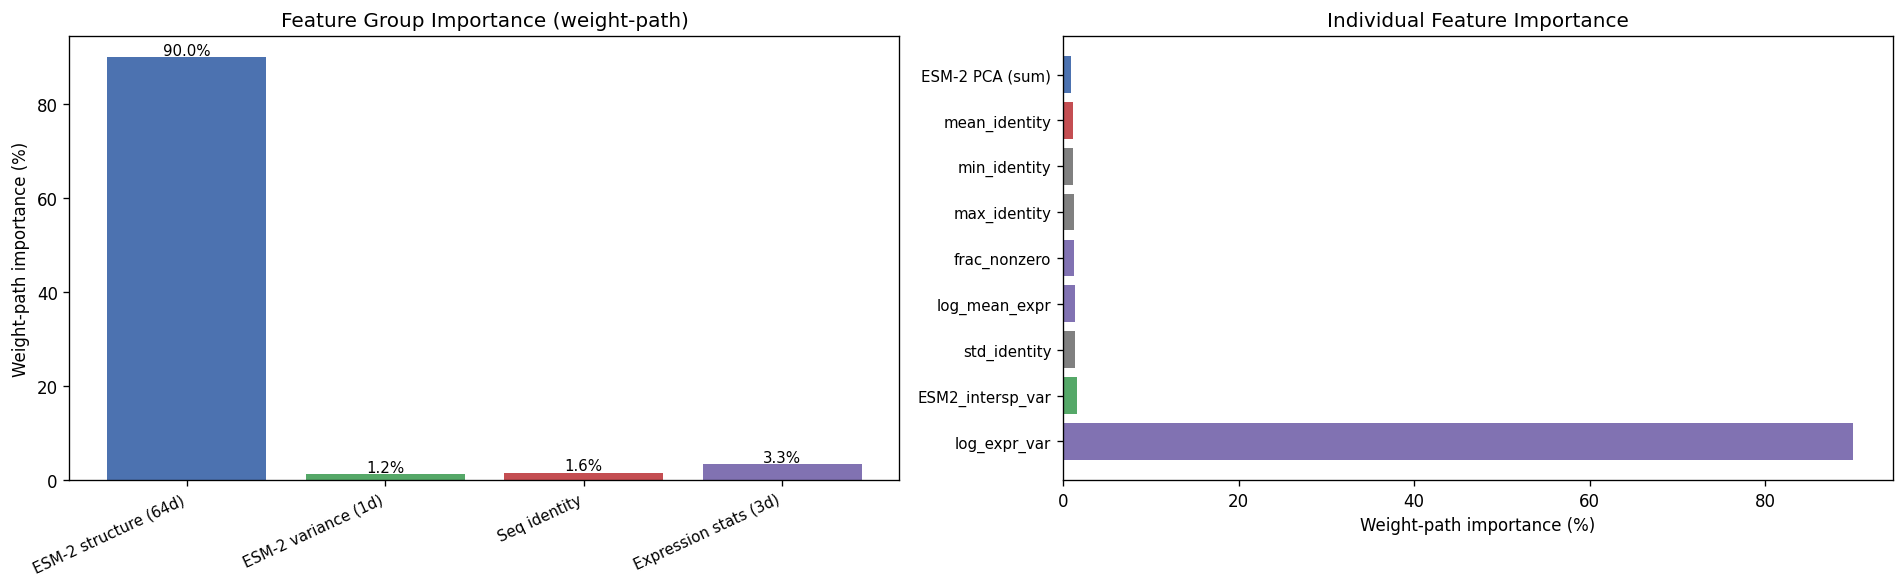


=== Weight-Path Feature Group Importance ===
  ESM-2 structure (64d)       90.0%  (1.4% per dim)
  Expression stats (3d)        3.3%  (1.1% per dim)
  Seq identity                 1.6%  (1.6% per dim)
  ESM-2 variance (1d)          1.2%  (1.2% per dim)


In [4]:
# Weight-path importance: |W2| @ |W1|
weight_importance = (np.abs(W2) @ np.abs(W1)).squeeze()  # (72,)
weight_importance_pct = weight_importance / weight_importance.sum() * 100

# Group-level summary
group_importance = {}
for gname, idxs in GROUPS.items():
    group_importance[gname] = weight_importance_pct[idxs].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Group-level bar chart
ax = axes[0]
bars = ax.bar(range(len(group_importance)), list(group_importance.values()),
              color=[GROUP_COLORS[g] for g in group_importance])
ax.set_xticks(range(len(group_importance)))
ax.set_xticklabels(list(group_importance.keys()), rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Weight-path importance (%)")
ax.set_title("Feature Group Importance (weight-path)")
for bar, val in zip(bars, group_importance.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", fontsize=9)

# (b) Top scalar features vs ESM-2 aggregate
ax = axes[1]
scalar_imp = {FEATURE_NAMES[i]: weight_importance_pct[i] for i in range(64, D)}
scalar_imp["ESM-2 PCA (sum)"] = weight_importance_pct[:64].sum()
sorted_imp = dict(sorted(scalar_imp.items(), key=lambda x: -x[1]))
colors = ["#4C72B0" if k == "ESM-2 PCA (sum)" else
          GROUP_COLORS.get(feat_to_group.get(FEATURE_NAMES.index(k) if k in FEATURE_NAMES else -1, ""), "gray")
          for k in sorted_imp]
ax.barh(range(len(sorted_imp)), list(sorted_imp.values()), color=colors[::-1])
ax.set_yticks(range(len(sorted_imp)))
ax.set_yticklabels(list(sorted_imp.keys())[::-1], fontsize=9)
ax.set_xlabel("Weight-path importance (%)")
ax.set_title("Individual Feature Importance")

fig.tight_layout()
plt.show()

print("\n=== Weight-Path Feature Group Importance ===")
for g, v in sorted(group_importance.items(), key=lambda x: -x[1]):
    n = len(GROUPS[g])
    print(f"  {g:<25} {v:6.1f}%  ({v/n:.1f}% per dim)")

## 2. Gradient-Based Attribution

For each gene g, compute the exact Jacobian of correction w.r.t. input features:

$$\frac{\partial \text{correction}_g}{\partial x_j} = W_2 \cdot \text{diag}(1 - h_g^2) \cdot W_{1[:,j]}$$

where $h_g = \tanh(W_1 x_g + b_1)$ are the hidden activations.

This is **exact** for the 2-layer tanh network — no approximation needed.

In [5]:
# Compute hidden activations for all genes
H = np.tanh(X_feat @ W1.T + b1)  # (G, 32)

# Verify correction reconstruction
correction_recon = (H @ W2.T + b2).squeeze()  # (G,)
recon_err = np.abs(correction_recon - correction).max()
print(f"Correction reconstruction error: {recon_err:.2e} (should be ~0)")

# Compute per-gene Jacobian: d(correction)/d(x) for each gene
# J[g, j] = sum_k W2[k] * (1 - H[g,k]^2) * W1[k, j]
tanh_deriv = 1 - H**2  # (G, 32)
# Efficient: J = (tanh_deriv * W2) @ W1  where W2 is broadcast as (1,32)
J = (tanh_deriv * W2) @ W1  # (G, 72)

# Global importance: mean |gradient| across genes
grad_importance = np.abs(J).mean(axis=0)  # (72,)
grad_importance_pct = grad_importance / grad_importance.sum() * 100

# Split by positive vs negative correction
pos_mask = correction > 0.05
neg_mask = correction < -0.05
grad_pos = np.abs(J[pos_mask]).mean(axis=0) if pos_mask.sum() > 0 else np.zeros(D)
grad_neg = np.abs(J[neg_mask]).mean(axis=0) if neg_mask.sum() > 0 else np.zeros(D)

print(f"Genes with correction > 0.05: {pos_mask.sum()} ({pos_mask.mean():.1%})")
print(f"Genes with correction < -0.05: {neg_mask.sum()} ({neg_mask.mean():.1%})")

Correction reconstruction error: 1.19e-07 (should be ~0)
Genes with correction > 0.05: 2659 (31.5%)
Genes with correction < -0.05: 4771 (56.6%)


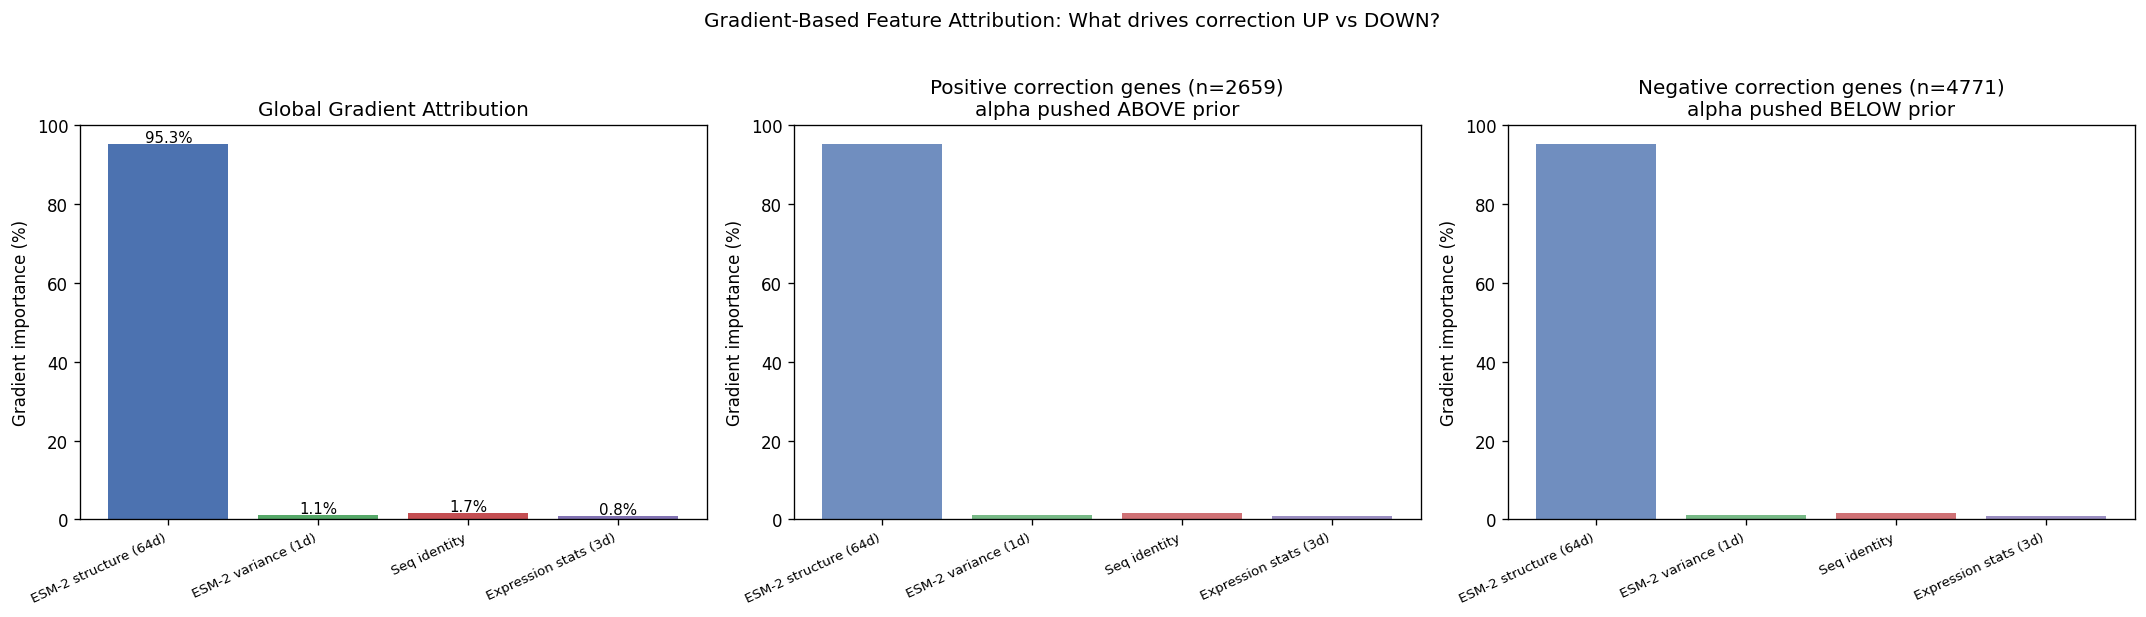

In [6]:
# Group-level gradient importance
grad_group_imp = {g: grad_importance_pct[idxs].sum() for g, idxs in GROUPS.items()}
grad_group_pos = {g: (grad_pos[idxs].sum() / grad_pos.sum() * 100) for g, idxs in GROUPS.items()}
grad_group_neg = {g: (grad_neg[idxs].sum() / grad_neg.sum() * 100) for g, idxs in GROUPS.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Global gradient importance by group
ax = axes[0]
bars = ax.bar(range(len(grad_group_imp)), list(grad_group_imp.values()),
              color=[GROUP_COLORS[g] for g in grad_group_imp])
ax.set_xticks(range(len(grad_group_imp)))
ax.set_xticklabels(list(grad_group_imp.keys()), rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Gradient importance (%)")
ax.set_title("Global Gradient Attribution")
for bar, val in zip(bars, grad_group_imp.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", fontsize=9)

# (b) Positive correction genes
ax = axes[1]
bars = ax.bar(range(len(grad_group_pos)), list(grad_group_pos.values()),
              color=[GROUP_COLORS[g] for g in grad_group_pos], alpha=0.8)
ax.set_xticks(range(len(grad_group_pos)))
ax.set_xticklabels(list(grad_group_pos.keys()), rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Gradient importance (%)")
ax.set_title(f"Positive correction genes (n={pos_mask.sum()})\nalpha pushed ABOVE prior")

# (c) Negative correction genes
ax = axes[2]
bars = ax.bar(range(len(grad_group_neg)), list(grad_group_neg.values()),
              color=[GROUP_COLORS[g] for g in grad_group_neg], alpha=0.8)
ax.set_xticks(range(len(grad_group_neg)))
ax.set_xticklabels(list(grad_group_neg.keys()), rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Gradient importance (%)")
ax.set_title(f"Negative correction genes (n={neg_mask.sum()})\nalpha pushed BELOW prior")

fig.suptitle("Gradient-Based Feature Attribution: What drives correction UP vs DOWN?", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

## 3. Integrated Gradients

Gold-standard attribution with the **completeness property**: attributions sum exactly to
the correction value for each gene.

$$\text{IG}_j(x_g) = x_{g,j} \cdot \frac{1}{M} \sum_{m=1}^{M} \frac{\partial \text{correction}}{\partial x_j}\bigg|_{x = \frac{m}{M} x_g}$$

Baseline: zero vector (= population mean in StandardScaled space).

In [7]:
# Integrated gradients: baseline = 0 (mean in StandardScaled space)
M = 100  # interpolation steps
IG = np.zeros_like(X_feat)  # (G, 72)

for m in range(1, M + 1):
    t = m / M
    X_interp = t * X_feat  # (G, 72)
    H_interp = np.tanh(X_interp @ W1.T + b1)  # (G, 32)
    tanh_d = 1 - H_interp**2  # (G, 32)
    J_interp = (tanh_d * W2) @ W1  # (G, 72)
    IG += J_interp

IG = X_feat * (IG / M)  # (G, 72) — element-wise attribution

# Verify completeness: sum of IG per gene should equal correction - correction_at_baseline
correction_baseline = float(b2)  # correction at x=0: W2 @ tanh(b1) + b2, but b1~0 initially...
H_base = np.tanh(b1)  # (32,)
correction_baseline = float(W2 @ H_base + b2)
ig_sum = IG.sum(axis=1)  # (G,)
completeness_err = np.abs(ig_sum - (correction - correction_baseline)).mean()
print(f"IG completeness error (mean): {completeness_err:.4f}")
print(f"Baseline correction (at x=0): {correction_baseline:.4f}")

# Global IG importance: mean |IG| across genes
ig_importance = np.abs(IG).mean(axis=0)  # (72,)
ig_importance_pct = ig_importance / ig_importance.sum() * 100

# IG by sign: positive IG = feature pushes correction in the positive direction
ig_positive = np.clip(IG, 0, None).mean(axis=0)  # features pushing correction up
ig_negative = np.clip(IG, None, 0).mean(axis=0)  # features pushing correction down

IG completeness error (mean): 0.0008
Baseline correction (at x=0): -0.0817


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_22206/2893363133.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  correction_baseline = float(b2)  # correction at x=0: W2 @ tanh(b1) + b2, but b1~0 initially...
/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_22206/2893363133.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  correction_baseline = float(W2 @ H_base + b2)


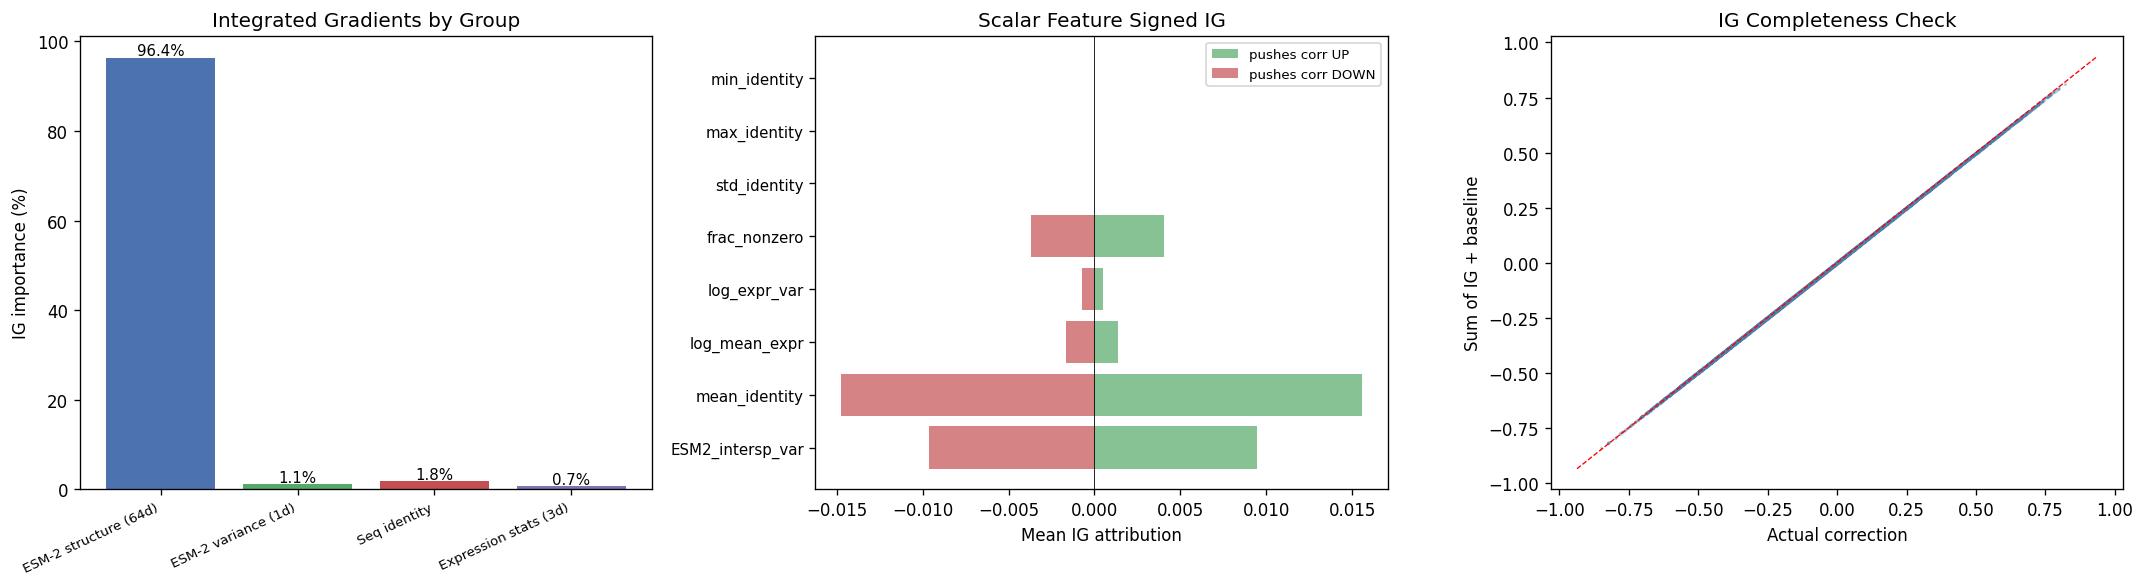

In [8]:
# Visualize IG results
ig_group_imp = {g: ig_importance_pct[idxs].sum() for g, idxs in GROUPS.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) IG group importance
ax = axes[0]
bars = ax.bar(range(len(ig_group_imp)), list(ig_group_imp.values()),
              color=[GROUP_COLORS[g] for g in ig_group_imp])
ax.set_xticks(range(len(ig_group_imp)))
ax.set_xticklabels(list(ig_group_imp.keys()), rotation=25, ha="right", fontsize=8)
ax.set_ylabel("IG importance (%)")
ax.set_title("Integrated Gradients by Group")
for bar, val in zip(bars, ig_group_imp.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", fontsize=9)

# (b) IG for scalar features: signed contribution
ax = axes[1]
scalar_ig_pos = {SCALAR_NAMES[i]: ig_positive[64+i] for i in range(8)}
scalar_ig_neg = {SCALAR_NAMES[i]: ig_negative[64+i] for i in range(8)}
y_pos = range(8)
ax.barh(y_pos, list(scalar_ig_pos.values()), color="#55A868", alpha=0.7, label="pushes corr UP")
ax.barh(y_pos, list(scalar_ig_neg.values()), color="#C44E52", alpha=0.7, label="pushes corr DOWN")
ax.set_yticks(y_pos)
ax.set_yticklabels(SCALAR_NAMES, fontsize=9)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("Mean IG attribution")
ax.set_title("Scalar Feature Signed IG")
ax.legend(fontsize=8)

# (c) IG completeness check
ax = axes[2]
ax.scatter(correction, ig_sum + correction_baseline, s=1, alpha=0.3, c="steelblue")
lim = max(abs(correction).max(), abs(ig_sum + correction_baseline).max()) * 1.1
ax.plot([-lim, lim], [-lim, lim], "r--", linewidth=0.8)
ax.set_xlabel("Actual correction")
ax.set_ylabel("Sum of IG + baseline")
ax.set_title("IG Completeness Check")

fig.tight_layout()
plt.show()

## 4. Feature Group Ablation

Direct causal test: zero out each feature group (set to StandardScaled mean = 0) and
measure the change in correction across all genes. This accounts for nonlinearities
and feature interactions that weight/gradient methods may miss.

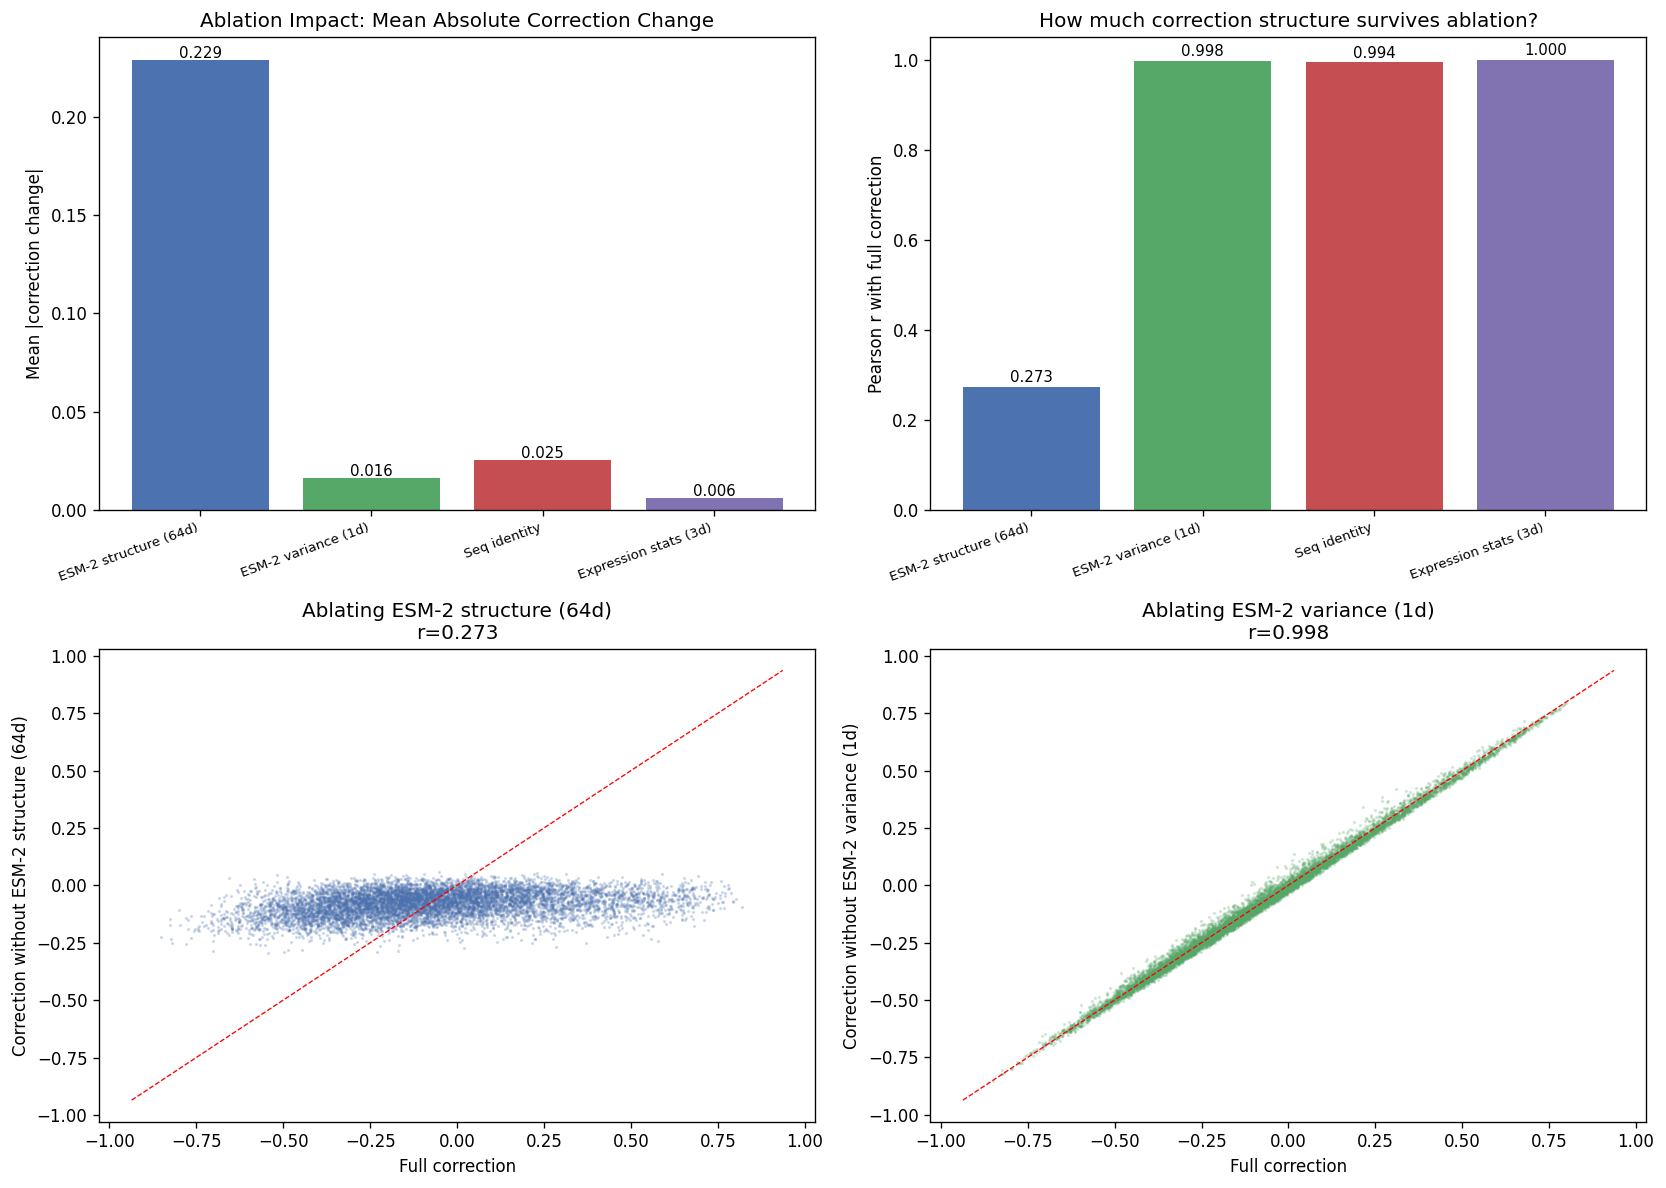


=== Ablation Summary ===
  ESM-2 structure (64d)      mean|Δ|=0.2293  max|Δ|=0.9161  r=0.273
  ESM-2 variance (1d)        mean|Δ|=0.0161  max|Δ|=0.1253  r=0.998
  Seq identity               mean|Δ|=0.0251  max|Δ|=0.2247  r=0.994
  Expression stats (3d)      mean|Δ|=0.0061  max|Δ|=0.0939  r=1.000


In [9]:
def compute_correction(X_in):
    """Compute GIN correction from feature matrix."""
    h = np.tanh(X_in @ W1.T + b1)
    return (h @ W2.T + b2).squeeze()

corr_full = compute_correction(X_feat)  # baseline

ablation_results = {}
for gname, idxs in GROUPS.items():
    X_ablated = X_feat.copy()
    X_ablated[:, idxs] = 0.0  # set to StandardScaled mean
    corr_ablated = compute_correction(X_ablated)
    delta = corr_full - corr_ablated
    ablation_results[gname] = {
        "mean_abs_change": np.abs(delta).mean(),
        "max_abs_change": np.abs(delta).max(),
        "std_change": delta.std(),
        "corr_with_original": np.corrcoef(corr_full, corr_ablated)[0, 1],
        "delta": delta,
        "ablated_corr": corr_ablated,
    }

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Mean absolute change by group
ax = axes[0, 0]
changes = [ablation_results[g]["mean_abs_change"] for g in GROUPS]
bars = ax.bar(range(len(GROUPS)), changes, color=[GROUP_COLORS[g] for g in GROUPS])
ax.set_xticks(range(len(GROUPS)))
ax.set_xticklabels(list(GROUPS.keys()), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Mean |correction change|")
ax.set_title("Ablation Impact: Mean Absolute Correction Change")
for bar, val in zip(bars, changes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f"{val:.3f}", ha="center", fontsize=9)

# (b) Correlation preservation
ax = axes[0, 1]
corrs = [ablation_results[g]["corr_with_original"] for g in GROUPS]
bars = ax.bar(range(len(GROUPS)), corrs, color=[GROUP_COLORS[g] for g in GROUPS])
ax.set_xticks(range(len(GROUPS)))
ax.set_xticklabels(list(GROUPS.keys()), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Pearson r with full correction")
ax.set_title("How much correction structure survives ablation?")
ax.set_ylim(0, 1.05)
for bar, val in zip(bars, corrs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{val:.3f}", ha="center", fontsize=9)

# (c-d) Scatter: full correction vs ablated correction for each group
for idx, (gname, res) in enumerate(ablation_results.items()):
    row, col = 1, idx % 2
    if idx >= 2:
        break
    ax = axes[row, col]
    ax.scatter(corr_full, res["ablated_corr"], s=1, alpha=0.2, c=GROUP_COLORS[gname])
    lim_v = max(abs(corr_full).max(), abs(res["ablated_corr"]).max()) * 1.1
    ax.plot([-lim_v, lim_v], [-lim_v, lim_v], "r--", linewidth=0.8)
    ax.set_xlabel("Full correction")
    ax.set_ylabel(f"Correction without {gname}")
    ax.set_title(f"Ablating {gname}\nr={res['corr_with_original']:.3f}")

fig.tight_layout()
plt.show()

print("\n=== Ablation Summary ===")
for g in GROUPS:
    r = ablation_results[g]
    print(f"  {g:<25}  mean|Δ|={r['mean_abs_change']:.4f}  "
          f"max|Δ|={r['max_abs_change']:.4f}  r={r['corr_with_original']:.3f}")

## 5. Partial Dependence Plots

For the top-importance scalar features: vary one feature from -3σ to +3σ while holding
all other features at their actual values. Shows the **direction and shape** of each
feature's effect on the correction.

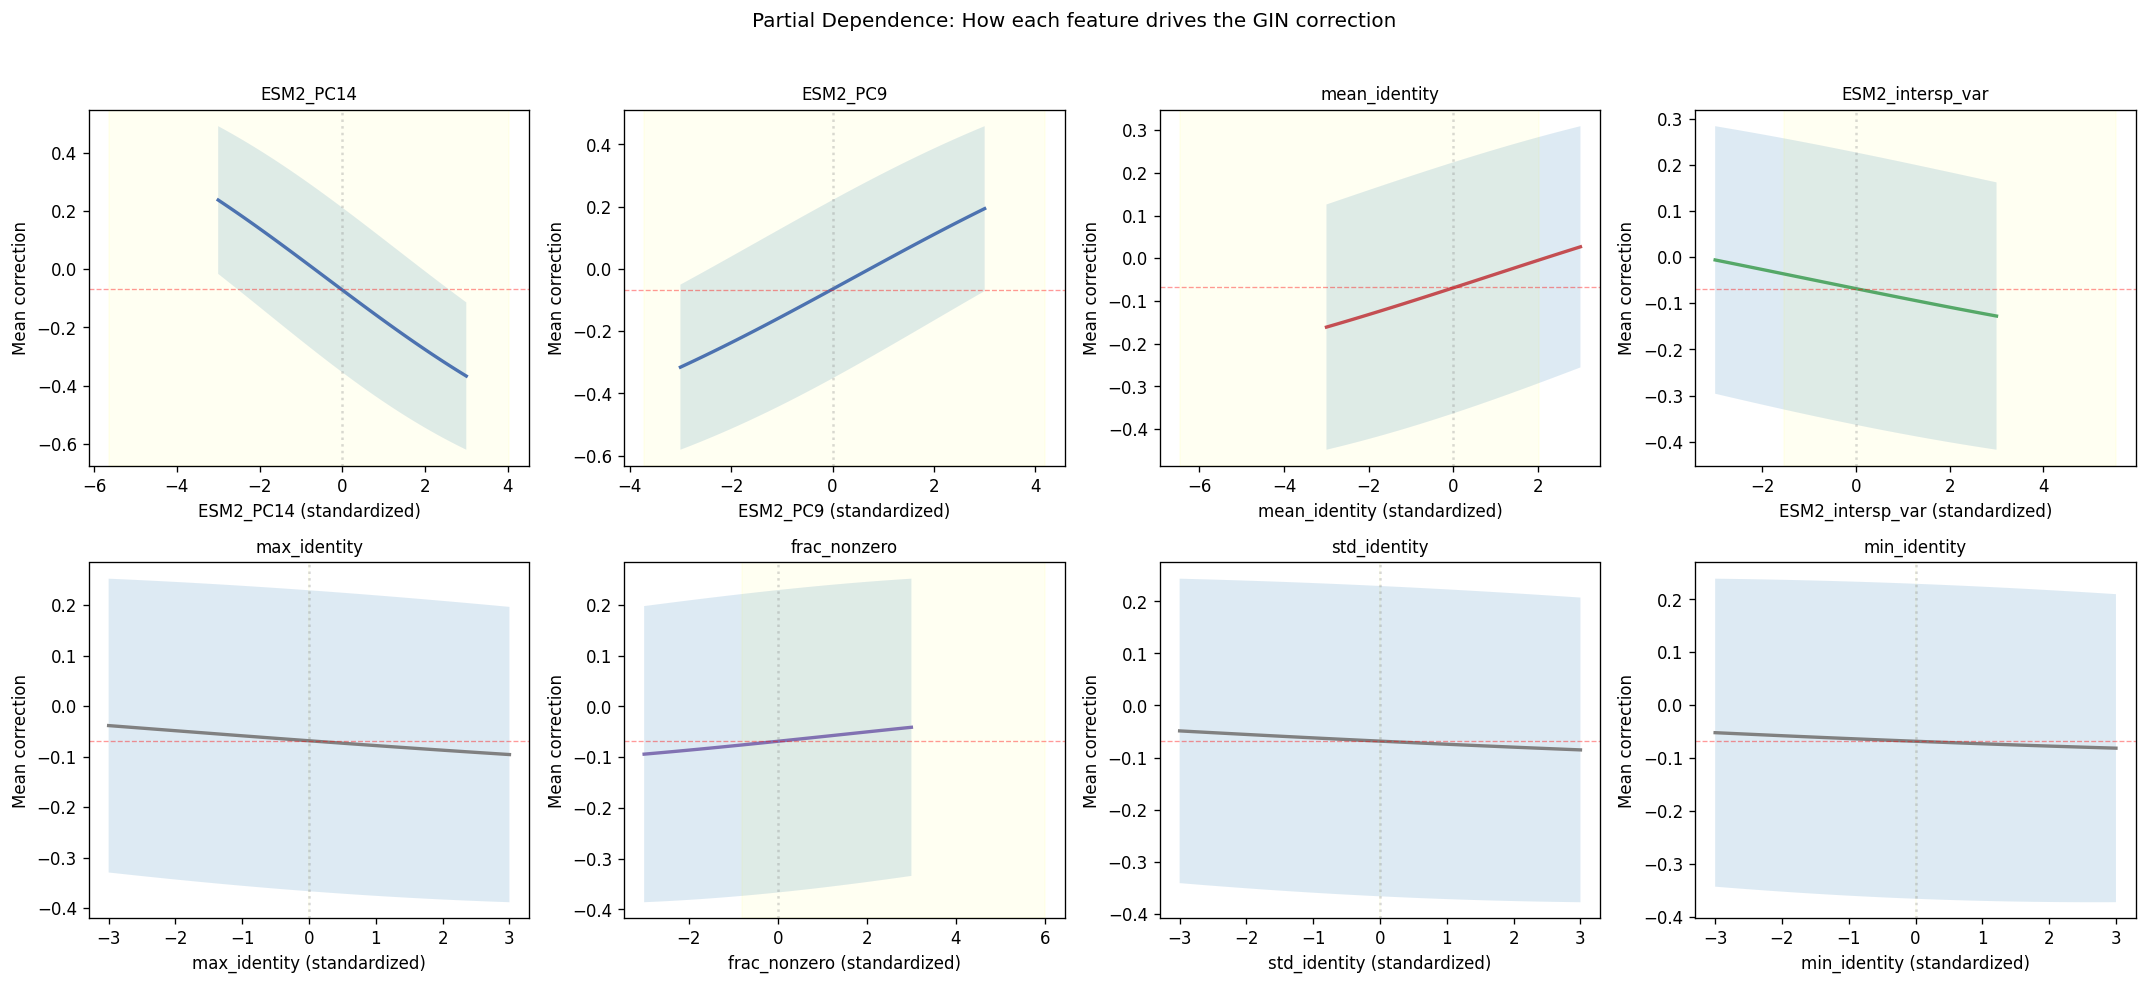

In [10]:
# Select top scalar features by gradient importance
scalar_grad_imp = {FEATURE_NAMES[i]: grad_importance[i] for i in range(64, D)}
top_scalars = sorted(scalar_grad_imp.items(), key=lambda x: -x[1])[:6]

# Also include top 2 ESM-2 PCs
esm2_grad_imp = {FEATURE_NAMES[i]: grad_importance[i] for i in range(64)}
top_esm2 = sorted(esm2_grad_imp.items(), key=lambda x: -x[1])[:2]

features_for_pdp = [(FEATURE_NAMES.index(n), n) for n, _ in top_esm2 + top_scalars]

grid = np.linspace(-3, 3, 50)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (feat_idx, feat_name) in zip(axes.flat, features_for_pdp):
    pdp_mean = []
    pdp_std = []
    for val in grid:
        X_mod = X_feat.copy()
        X_mod[:, feat_idx] = val
        c = compute_correction(X_mod)
        pdp_mean.append(c.mean())
        pdp_std.append(c.std())
    pdp_mean = np.array(pdp_mean)
    pdp_std = np.array(pdp_std)
    
    ax.plot(grid, pdp_mean, color=GROUP_COLORS.get(feat_to_group.get(feat_idx, ""), "gray"), linewidth=2)
    ax.fill_between(grid, pdp_mean - pdp_std, pdp_mean + pdp_std, alpha=0.15)
    ax.axhline(correction.mean(), color="red", linestyle="--", alpha=0.4, linewidth=0.8)
    ax.axvline(0, color="gray", linestyle=":", alpha=0.3)
    # Mark actual data range
    actual_min, actual_max = X_feat[:, feat_idx].min(), X_feat[:, feat_idx].max()
    ax.axvspan(actual_min, actual_max, alpha=0.05, color="yellow")
    ax.set_xlabel(f"{feat_name} (standardized)")
    ax.set_ylabel("Mean correction")
    ax.set_title(feat_name, fontsize=10)

fig.suptitle("Partial Dependence: How each feature drives the GIN correction", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

## 6. Hidden Neuron Analysis

The GIN has 32 hidden neurons with tanh activation. Each neuron computes
$h_k = \tanh(w_{1,k} \cdot x + b_{1,k})$ and contributes $W_{2,k} \cdot h_k$
to the correction.

Questions:
- Which neurons are most important (largest |W2|)?
- What feature patterns does each neuron detect?
- Are any neurons saturated (always near ±1)?

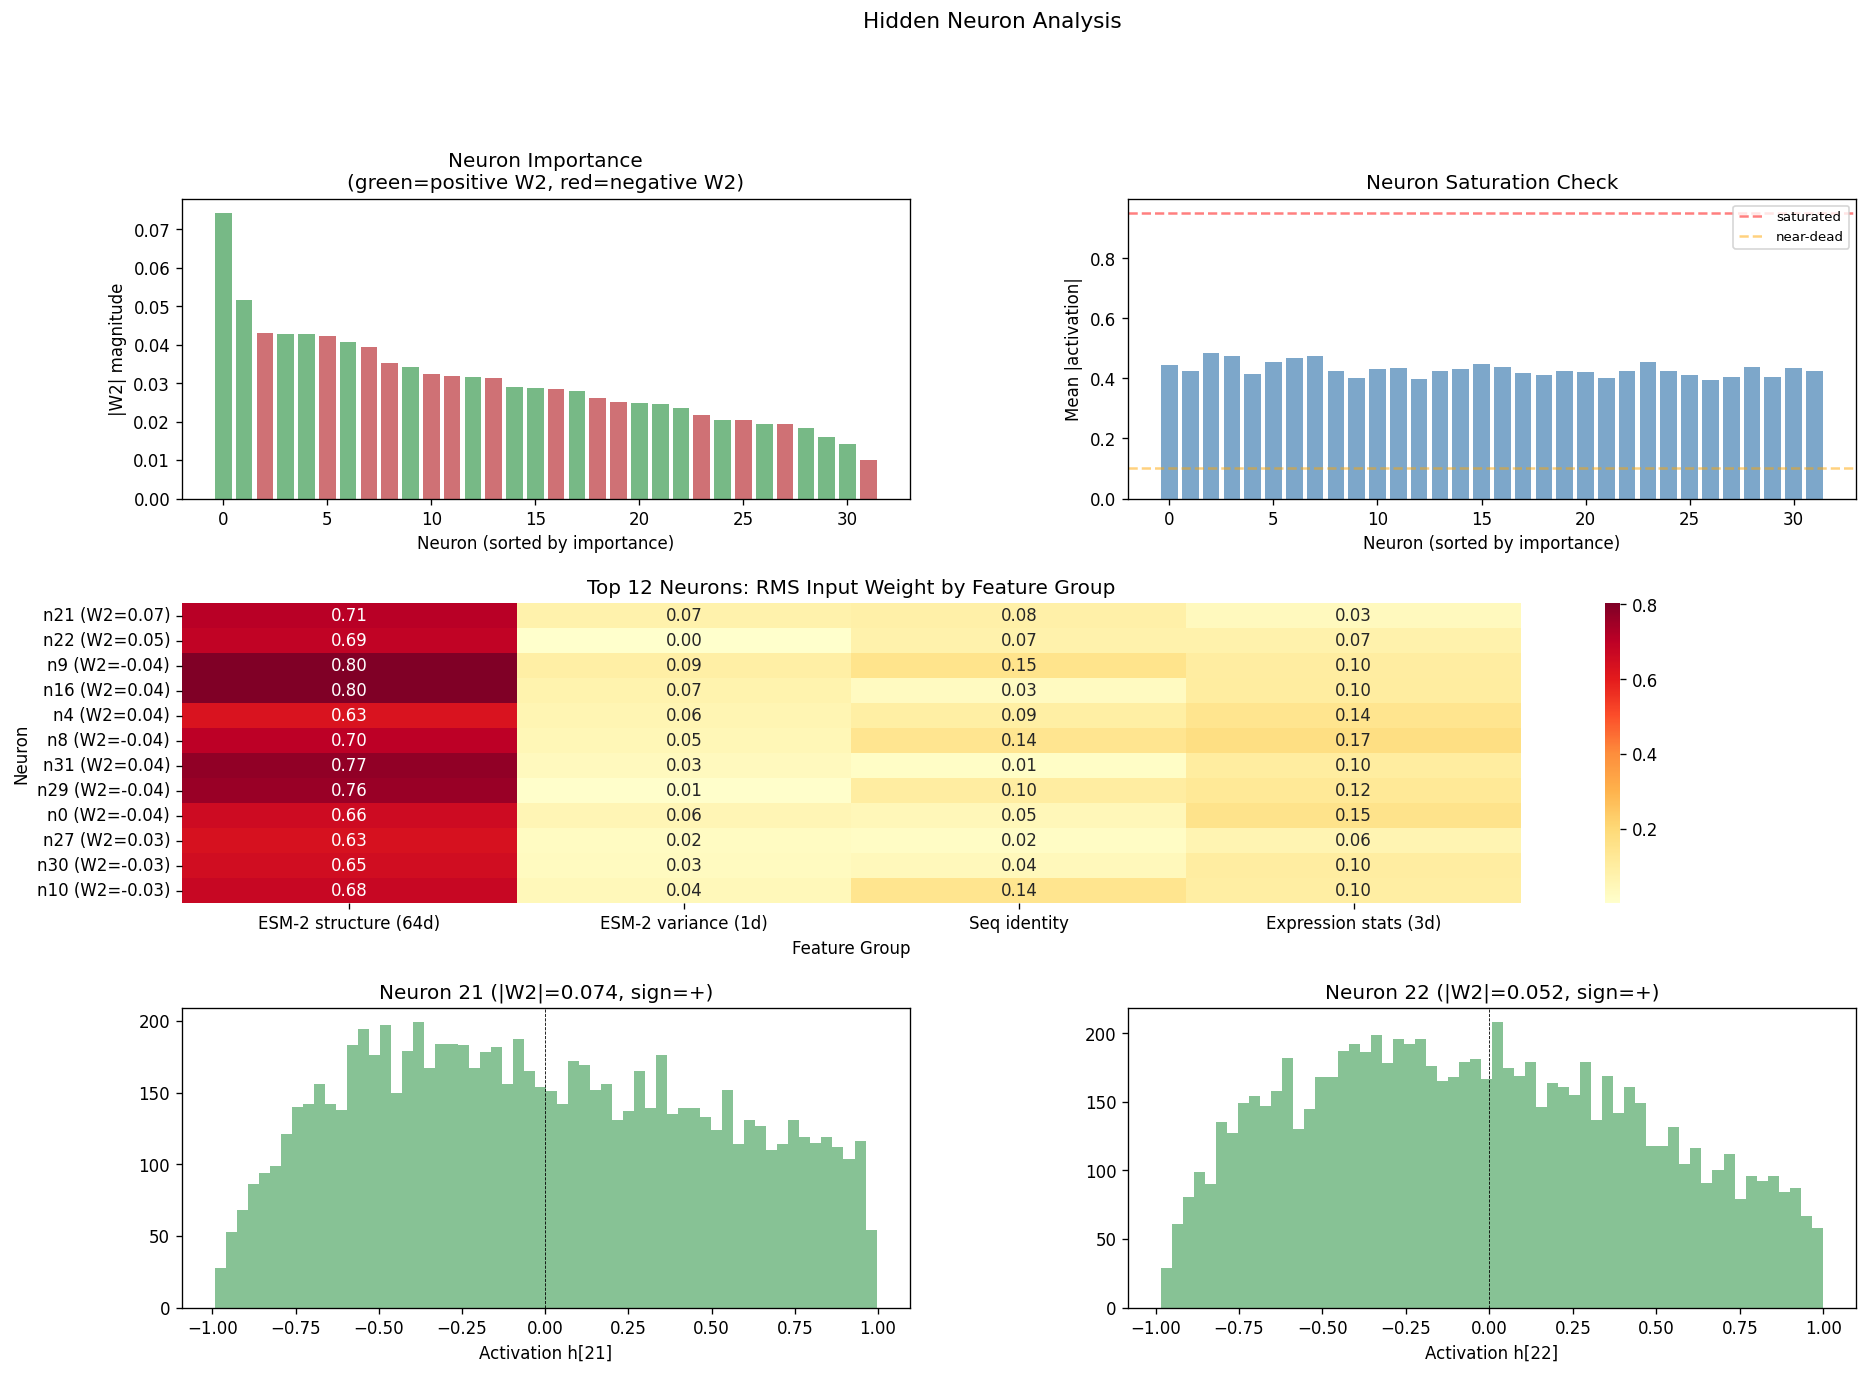


Saturated neurons (mean|h|>0.95): 0/32
Near-dead neurons (mean|h|<0.1): 0/32
Top 5 neurons account for 26.2% of total |W2|


In [11]:
# Neuron importance: |W2| magnitude
neuron_importance = np.abs(W2).squeeze()  # (32,)
neuron_sign = np.sign(W2).squeeze()  # (32,) — positive W2 means neuron pushes correction up when active
neuron_order = np.argsort(-neuron_importance)

# Hidden activations across all genes
# H already computed: (G, 32)

fig = plt.figure(figsize=(18, 12))
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.3)

# (a) Neuron importance (|W2|) sorted
ax = fig.add_subplot(gs[0, 0])
colors_n = ["#55A868" if neuron_sign[k] > 0 else "#C44E52" for k in neuron_order]
ax.bar(range(32), neuron_importance[neuron_order], color=colors_n, alpha=0.8)
ax.set_xlabel("Neuron (sorted by importance)")
ax.set_ylabel("|W2| magnitude")
ax.set_title("Neuron Importance\n(green=positive W2, red=negative W2)")

# (b) Neuron saturation check
ax = fig.add_subplot(gs[0, 1])
mean_abs_h = np.abs(H).mean(axis=0)  # mean |activation| per neuron
ax.bar(range(32), mean_abs_h[neuron_order], color="steelblue", alpha=0.7)
ax.axhline(0.95, color="red", linestyle="--", alpha=0.5, label="saturated")
ax.axhline(0.1, color="orange", linestyle="--", alpha=0.5, label="near-dead")
ax.set_xlabel("Neuron (sorted by importance)")
ax.set_ylabel("Mean |activation|")
ax.set_title("Neuron Saturation Check")
ax.legend(fontsize=8)

# (c) Weight heatmap: top 10 neurons x feature groups
ax = fig.add_subplot(gs[1, :])
top_neurons = neuron_order[:12]
# Aggregate W1 by feature group for each neuron
group_names_short = list(GROUPS.keys())
w1_by_group = np.zeros((len(top_neurons), len(GROUPS)))
for i, k in enumerate(top_neurons):
    for j, (gn, idxs) in enumerate(GROUPS.items()):
        w1_by_group[i, j] = np.sqrt((W1[k, idxs]**2).sum())  # RMS weight to group

sns.heatmap(w1_by_group, annot=True, fmt=".2f", cmap="YlOrRd",
            xticklabels=group_names_short, 
            yticklabels=[f"n{k} (W2={W2[0,k]:.2f})" for k in top_neurons],
            ax=ax)
ax.set_title("Top 12 Neurons: RMS Input Weight by Feature Group")
ax.set_xlabel("Feature Group")
ax.set_ylabel("Neuron")

# (d) Activation distribution for top 4 neurons
for panel_idx, nk in enumerate(neuron_order[:4]):
    if panel_idx >= 2:
        break
    ax = fig.add_subplot(gs[2, panel_idx])
    ax.hist(H[:, nk], bins=60, color=colors_n[panel_idx], alpha=0.7, edgecolor="none")
    ax.axvline(0, color="black", linestyle="--", linewidth=0.5)
    ax.set_xlabel(f"Activation h[{nk}]")
    ax.set_title(f"Neuron {nk} (|W2|={neuron_importance[nk]:.3f}, sign={'+' if neuron_sign[nk]>0 else '-'})")

fig.suptitle("Hidden Neuron Analysis", fontsize=13, y=1.01)
plt.show()

# Summary
n_saturated = (mean_abs_h > 0.95).sum()
n_dead = (mean_abs_h < 0.1).sum()
print(f"\nSaturated neurons (mean|h|>0.95): {n_saturated}/32")
print(f"Near-dead neurons (mean|h|<0.1): {n_dead}/32")
print(f"Top 5 neurons account for {neuron_importance[neuron_order[:5]].sum()/neuron_importance.sum()*100:.1f}% of total |W2|")

## 7. Per-Gene Correction Decomposition

For each gene, decompose its correction into contributions from each hidden neuron:

$$\text{correction}_g = \sum_{k=1}^{32} W_{2,k} \cdot \tanh(w_{1,k} \cdot x_g + b_{1,k}) + b_2$$

Focus on the top positive and negative delta-alpha genes to understand
what drives the most interesting integration decisions.

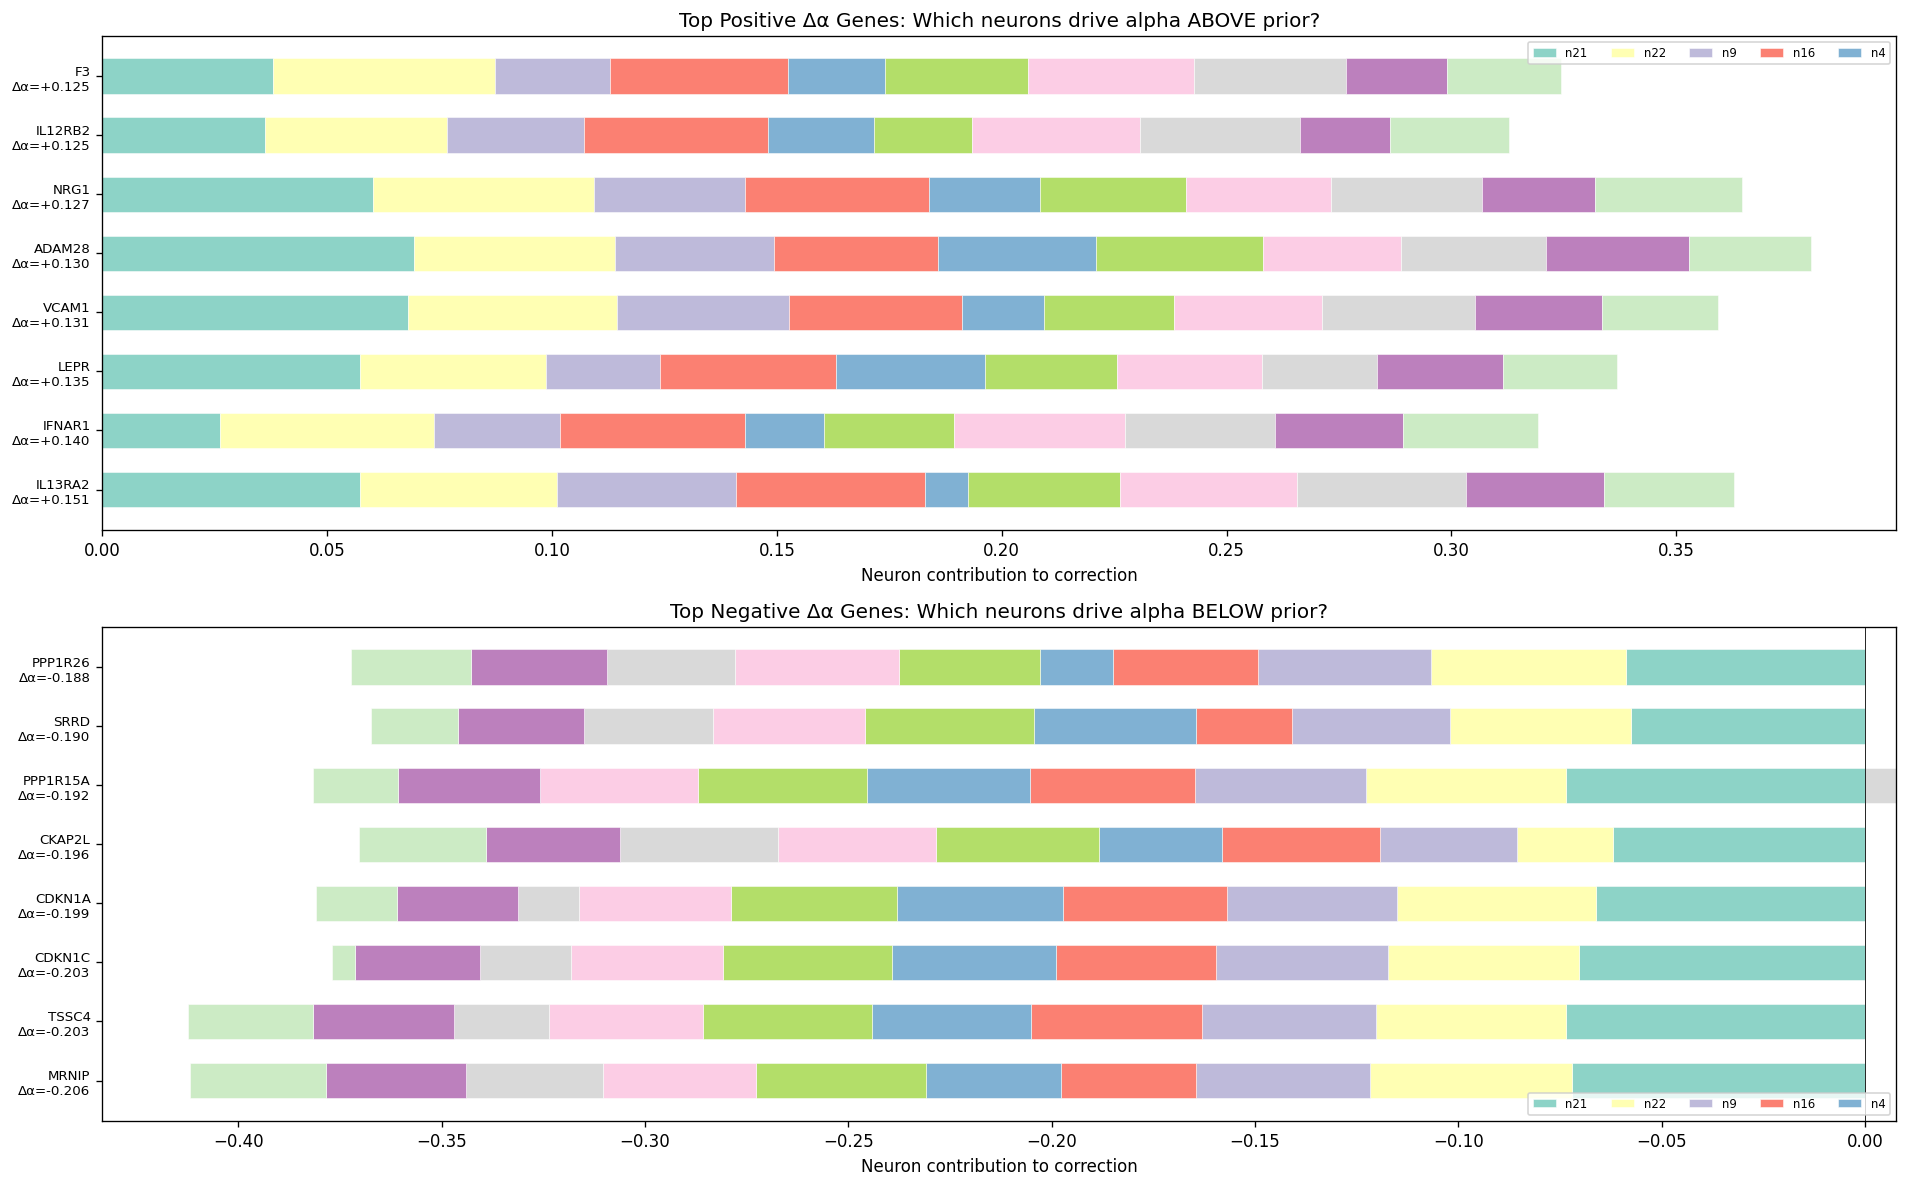

In [12]:
# Per-neuron contribution: W2[k] * H[g, k]
neuron_contrib = H * W2  # (G, 32) — broadcasting W2 (1,32)

# Select top positive and negative delta-alpha genes
N_TOP = 8
top_pos_idx = np.argsort(-delta_alpha)[:N_TOP]
top_neg_idx = np.argsort(delta_alpha)[:N_TOP]

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

for ax_idx, (gene_indices, title) in enumerate([
    (top_pos_idx, "Top Positive Δα Genes: Which neurons drive alpha ABOVE prior?"),
    (top_neg_idx, "Top Negative Δα Genes: Which neurons drive alpha BELOW prior?"),
]):
    ax = axes[ax_idx]
    data = neuron_contrib[gene_indices][:, neuron_order[:10]]
    bottom_pos = np.zeros(N_TOP)
    bottom_neg = np.zeros(N_TOP)
    for ni in range(10):
        vals = data[:, ni]
        pos_vals = np.clip(vals, 0, None)
        neg_vals = np.clip(vals, None, 0)
        ax.barh(range(N_TOP), pos_vals, left=bottom_pos, height=0.6,
                label=f"n{neuron_order[ni]}" if ni < 5 else None,
                color=plt.cm.Set3(ni/10), edgecolor="white", linewidth=0.3)
        ax.barh(range(N_TOP), neg_vals, left=bottom_neg, height=0.6,
                color=plt.cm.Set3(ni/10), edgecolor="white", linewidth=0.3)
        bottom_pos += pos_vals
        bottom_neg += neg_vals
    ax.set_yticks(range(N_TOP))
    ax.set_yticklabels([f"{real_names[i]}\nΔα={delta_alpha[i]:+.3f}" for i in gene_indices], fontsize=8)
    ax.axvline(0, color="black", linewidth=0.5)
    ax.set_xlabel("Neuron contribution to correction")
    ax.set_title(title)
    ax.legend(fontsize=7, ncol=5, loc="upper right" if ax_idx == 0 else "lower right")

fig.tight_layout()
plt.show()

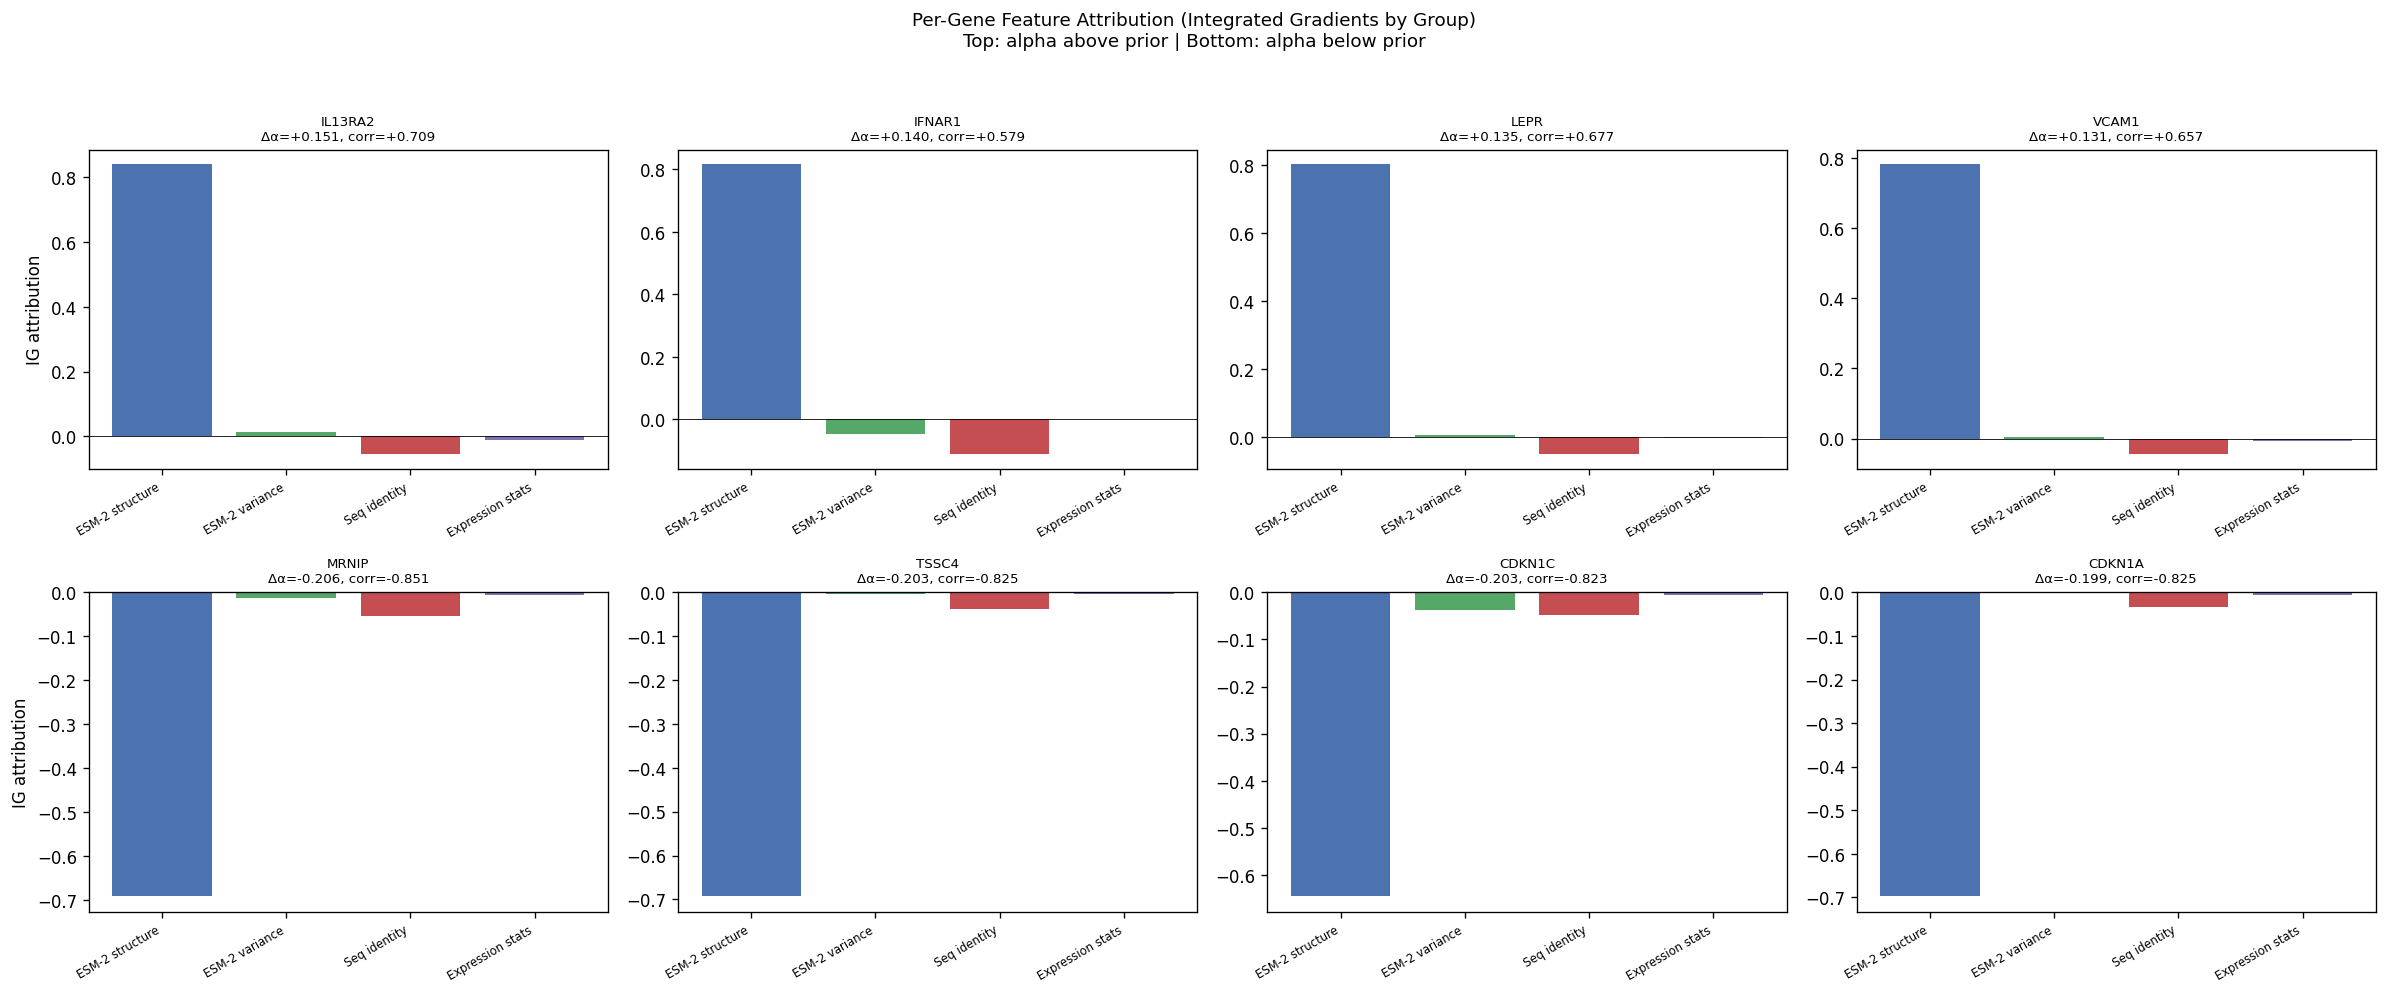

In [13]:
# Trace back to features: for top genes, which input features matter most?
# Use per-gene IG to attribute correction to input features

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for row, (gene_indices, title_prefix) in enumerate([
    (top_pos_idx[:4], "Positive Δα"),
    (top_neg_idx[:4], "Negative Δα"),
]):
    for col, g_idx in enumerate(gene_indices):
        ax = axes[row, col]
        ig_gene = IG[g_idx]
        group_ig = {}
        for gname, idxs in GROUPS.items():
            group_ig[gname] = ig_gene[idxs].sum()
        
        colors_bar = [GROUP_COLORS[g] for g in group_ig]
        ax.bar(range(len(group_ig)), list(group_ig.values()), color=colors_bar)
        ax.set_xticks(range(len(group_ig)))
        ax.set_xticklabels([g.split("(")[0].strip() for g in group_ig], 
                          rotation=30, ha="right", fontsize=7)
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(f"{real_names[g_idx]}\nΔα={delta_alpha[g_idx]:+.3f}, corr={correction[g_idx]:+.3f}", fontsize=8)
        ax.set_ylabel("IG attribution" if col == 0 else "")

fig.suptitle("Per-Gene Feature Attribution (Integrated Gradients by Group)\nTop: alpha above prior | Bottom: alpha below prior",
             fontsize=11, y=1.03)
fig.tight_layout()
plt.show()

## 8. Feature Importance Consensus

Compare all four attribution methods to identify features that consistently matter.

  FEATURE GROUP IMPORTANCE CONSENSUS (% of total)
                       Weight-path (%)  Gradient (%)  Integ. Grad. (%)  Ablation (%)
ESM-2 structure (64d)             90.0     95.300003         96.400002          98.8
ESM-2 variance (1d)                1.2      1.100000          1.100000           0.3
Seq identity                       1.6      1.700000          1.800000           0.8
Expression stats (3d)              3.3      0.800000          0.700000           0.1

  PER-DIMENSION IMPORTANCE (% / dim)
                       Weight-path (%)  Gradient (%)  Integ. Grad. (%)  Ablation (%)
ESM-2 structure (64d)             1.41          1.49              1.51          1.54
ESM-2 variance (1d)               1.17          1.07              1.12          0.34
Seq identity                      1.56          1.67              1.78          0.76
Expression stats (3d)             1.11          0.27              0.23          0.02


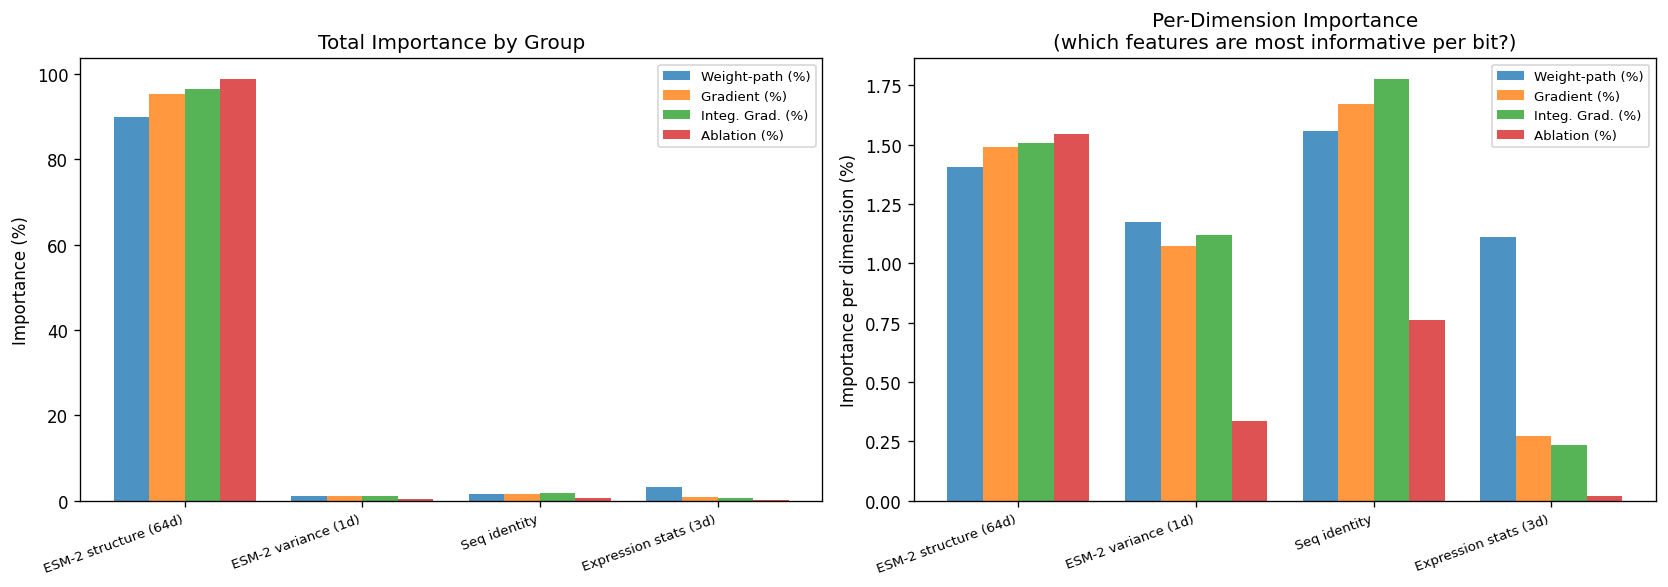

In [14]:
# Collect group-level importance from all methods
# For ablation, use 1 - correlation as disruption measure
abl_disruption = {g: 1 - ablation_results[g]["corr_with_original"] for g in GROUPS}
abl_total = sum(abl_disruption.values())
abl_pct = {g: v / abl_total * 100 if abl_total > 0 else 25 for g, v in abl_disruption.items()}

consensus_df = pd.DataFrame({
    "Weight-path (%)": {g: weight_importance_pct[GROUPS[g]].sum() for g in GROUPS},
    "Gradient (%)": {g: grad_importance_pct[GROUPS[g]].sum() for g in GROUPS},
    "Integ. Grad. (%)": {g: ig_importance_pct[GROUPS[g]].sum() for g in GROUPS},
    "Ablation (%)": abl_pct,
})

# Add per-dim importance (normalize by group size)
consensus_per_dim = consensus_df.copy()
for g in GROUPS:
    n = len(GROUPS[g])
    for col in consensus_per_dim.columns:
        consensus_per_dim.loc[g, col] /= n

print("=" * 70)
print("  FEATURE GROUP IMPORTANCE CONSENSUS (% of total)")
print("=" * 70)
print(consensus_df.round(1).to_string())
print()
print("=" * 70)
print("  PER-DIMENSION IMPORTANCE (% / dim)")
print("=" * 70)
print(consensus_per_dim.round(2).to_string())

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
x = np.arange(len(GROUPS))
width = 0.2
for i, col in enumerate(consensus_df.columns):
    ax.bar(x + i * width, consensus_df[col].values, width, label=col, alpha=0.8)
ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(list(GROUPS.keys()), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Importance (%)")
ax.set_title("Total Importance by Group")
ax.legend(fontsize=8)

ax = axes[1]
for i, col in enumerate(consensus_per_dim.columns):
    ax.bar(x + i * width, consensus_per_dim[col].values, width, label=col, alpha=0.8)
ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(list(GROUPS.keys()), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Importance per dimension (%)")
ax.set_title("Per-Dimension Importance\n(which features are most informative per bit?)")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## 9. Scalar Feature Deep-Dive

Individual scalar features (8 non-ESM2 features) are directly interpretable.
Analyze their relationship to delta-alpha and biological meaning.

=== Scalar Feature Correlations with Model Outputs ===
                  r(feature, Δα)  p(Δα)  r(feature, corr)  r(feature, α)  Grad importance (%)  IG importance (%)
Feature                                                                                                         
ESM2_intersp_var          -0.225    0.0            -0.217         -0.292                1.074              1.120
mean_identity              0.294    0.0             0.231          0.921                1.671              1.776
log_mean_expr              0.074    0.0             0.068          0.200                0.209              0.177
log_expr_var               0.099    0.0             0.094          0.202                0.137              0.071
frac_nonzero               0.057    0.0             0.050          0.198                0.473              0.454


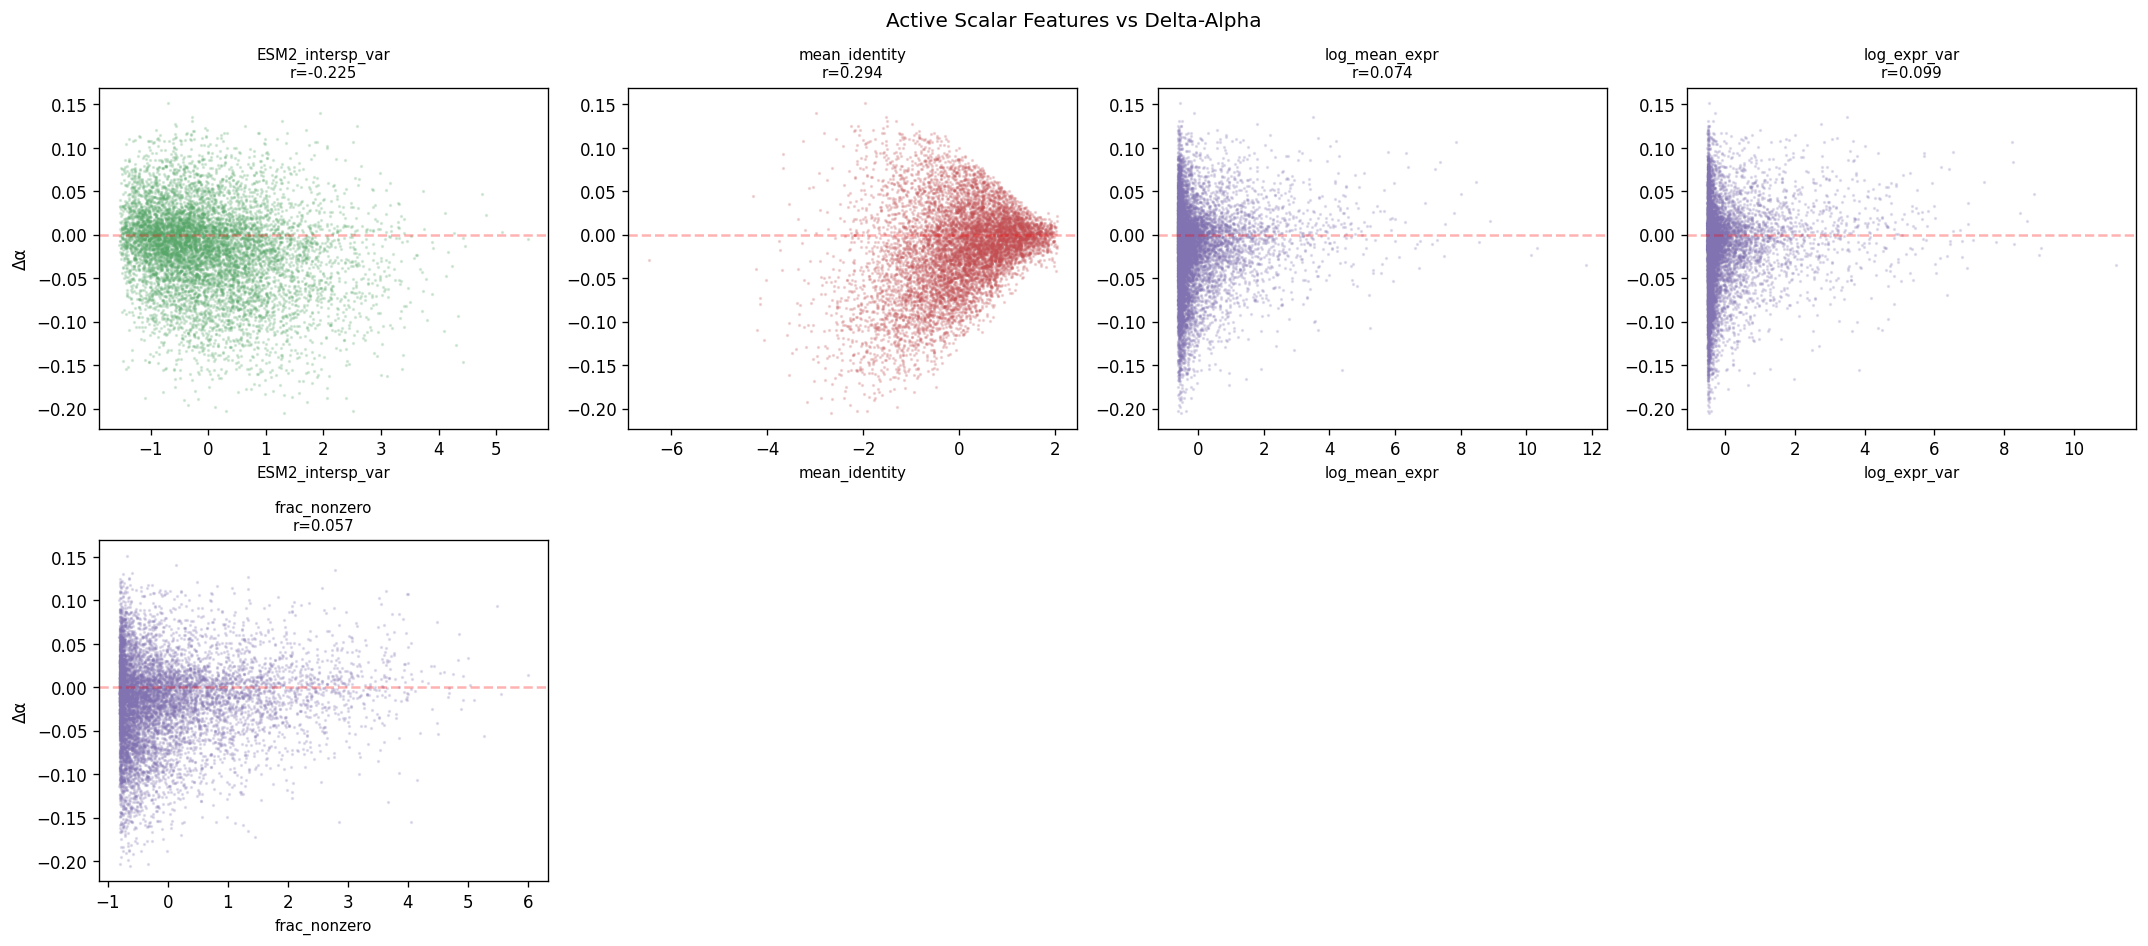

In [15]:
# Correlation between each active scalar feature and delta-alpha / correction
scalar_analysis = []
for i in active_scalars:
    name = SCALAR_NAMES[i]
    feat_vals = X_feat[:, 64 + i]
    r_da, p_da = spearmanr(feat_vals, delta_alpha)
    r_corr, _ = spearmanr(feat_vals, correction)
    r_alpha, _ = spearmanr(feat_vals, alpha)
    scalar_analysis.append({
        "Feature": name,
        "r(feature, Δα)": r_da,
        "p(Δα)": p_da,
        "r(feature, corr)": r_corr,
        "r(feature, α)": r_alpha,
        "Grad importance (%)": grad_importance_pct[64 + i],
        "IG importance (%)": ig_importance_pct[64 + i],
    })

scalar_df = pd.DataFrame(scalar_analysis).set_index("Feature")
print("=== Scalar Feature Correlations with Model Outputs ===")
print(scalar_df.round(3).to_string())

# Scatter plots for active features only
n_active = len(active_scalars)
n_cols = min(4, n_active)
n_rows = (n_active + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4 * n_rows), squeeze=False)
for idx, i in enumerate(active_scalars):
    ax = axes[idx // n_cols, idx % n_cols]
    name = SCALAR_NAMES[i]
    feat_vals = X_feat[:, 64 + i]
    r = spearmanr(feat_vals, delta_alpha).correlation
    ax.scatter(feat_vals, delta_alpha, s=1, alpha=0.2, 
              c=GROUP_COLORS.get(feat_to_group.get(64+i, ""), "gray"))
    ax.set_xlabel(name, fontsize=9)
    ax.set_ylabel("Δα" if idx % n_cols == 0 else "")
    ax.set_title(f"{name}\nr={r:.3f}", fontsize=9)
    ax.axhline(0, color="red", linestyle="--", alpha=0.3)
# Hide unused
for idx in range(n_active, n_rows * n_cols):
    axes[idx // n_cols, idx % n_cols].set_visible(False)

fig.suptitle("Active Scalar Features vs Delta-Alpha", fontsize=12)
fig.tight_layout()
plt.show()

## 10. ESM-2 PCA Component Analysis

The 64 ESM-2 PCA dimensions capture protein structural information.
Which PCs are most predictive of expression conservation (delta-alpha)?
This reveals the link between protein structure and expression conservation.

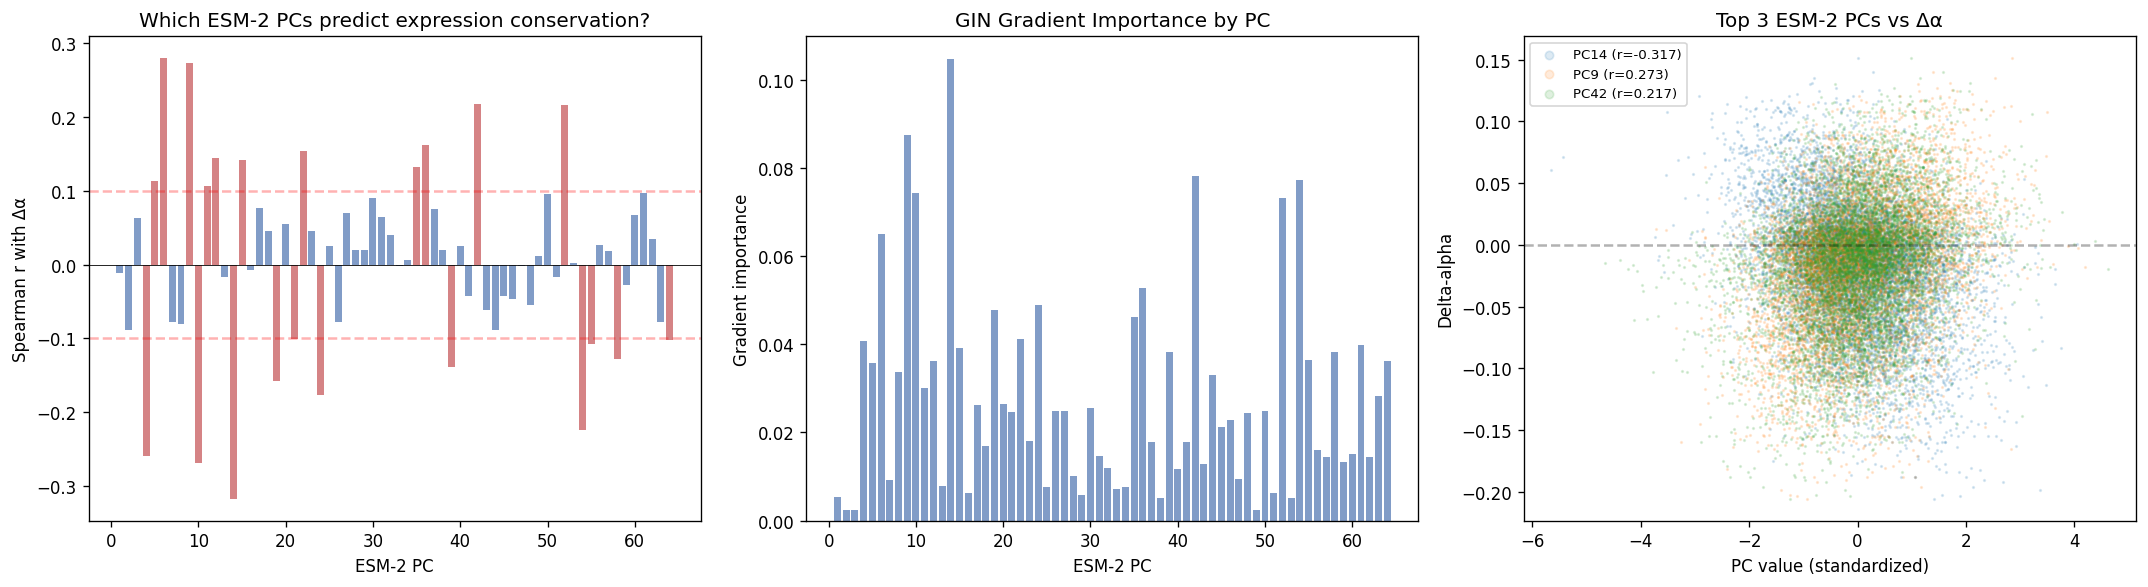


ESM-2 PCs with |r(Δα)| > 0.1: 22/64
 PC  r(PC, Δα)  grad_imp
  6   0.279747  0.065054
  9   0.272785  0.087413
 42   0.217169  0.078108
 52   0.216327  0.073194
 36   0.162448  0.052657
 22   0.153166  0.041308
 12   0.144596  0.036293
 15   0.141567  0.039091
 35   0.131749  0.046290
  5   0.112573  0.035726
 11   0.106278  0.029998
 21  -0.101262  0.024534
 64  -0.101805  0.036304
 55  -0.107854  0.036526
 58  -0.127413  0.038153
 39  -0.138155  0.038181
 19  -0.158419  0.047856
 24  -0.176461  0.048808
 54  -0.223734  0.077222
  4  -0.259282  0.040813
 10  -0.268601  0.074205
 14  -0.317137  0.104673


In [16]:
# Correlation of each ESM-2 PC with delta-alpha
esm2_correlations = []
for pc in range(64):
    r, p = spearmanr(X_feat[:, pc], delta_alpha)
    esm2_correlations.append({"PC": pc + 1, "r(PC, Δα)": r, "p": p,
                              "grad_imp": grad_importance[pc],
                              "ig_imp": ig_importance[pc]})

esm2_df = pd.DataFrame(esm2_correlations)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Correlation with delta-alpha by PC
ax = axes[0]
colors_pc = ["#C44E52" if abs(r) > 0.1 else "#4C72B0" for r in esm2_df["r(PC, Δα)"]]
ax.bar(esm2_df["PC"], esm2_df["r(PC, Δα)"], color=colors_pc, alpha=0.7)
ax.axhline(0, color="black", linewidth=0.5)
ax.axhline(0.1, color="red", linestyle="--", alpha=0.3)
ax.axhline(-0.1, color="red", linestyle="--", alpha=0.3)
ax.set_xlabel("ESM-2 PC")
ax.set_ylabel("Spearman r with Δα")
ax.set_title("Which ESM-2 PCs predict expression conservation?")

# (b) Gradient importance by PC
ax = axes[1]
ax.bar(esm2_df["PC"], esm2_df["grad_imp"], color="#4C72B0", alpha=0.7)
ax.set_xlabel("ESM-2 PC")
ax.set_ylabel("Gradient importance")
ax.set_title("GIN Gradient Importance by PC")

# (c) Top PCs: scatter with delta-alpha
ax = axes[2]
top_pcs = esm2_df.nlargest(3, "grad_imp")["PC"].values
for pc_num in top_pcs:
    r = spearmanr(X_feat[:, pc_num-1], delta_alpha).correlation
    ax.scatter(X_feat[:, pc_num-1], delta_alpha, s=1, alpha=0.15,
              label=f"PC{pc_num} (r={r:.3f})")
ax.axhline(0, color="black", linestyle="--", alpha=0.3)
ax.set_xlabel("PC value (standardized)")
ax.set_ylabel("Delta-alpha")
ax.set_title(f"Top {len(top_pcs)} ESM-2 PCs vs Δα")
ax.legend(fontsize=8, markerscale=5)

fig.tight_layout()
plt.show()

# Summary
sig_pcs = esm2_df[esm2_df["r(PC, Δα)"].abs() > 0.1]
print(f"\nESM-2 PCs with |r(Δα)| > 0.1: {len(sig_pcs)}/64")
if len(sig_pcs) > 0:
    print(sig_pcs.sort_values("r(PC, Δα)", ascending=False)[["PC", "r(PC, Δα)", "grad_imp"]].to_string(index=False))

## 11. Summary

Key findings from the GIN feature attribution analysis.

In [17]:
print("=" * 70)
print("  GIN FEATURE ATTRIBUTION — KEY FINDINGS")
print("=" * 70)
print()
print("1. FEATURE GROUP IMPORTANCE (consensus across 4 methods):")
mean_imp = consensus_df.mean(axis=1).sort_values(ascending=False)
for g in mean_imp.index:
    n = len(GROUPS[g])
    print(f"   {g:<25} {mean_imp[g]:5.1f}%  ({mean_imp[g]/n:.1f}% per dim)")

print(f"\n2. PER-DIMENSION ANALYSIS:")
mean_per_dim = consensus_per_dim.mean(axis=1).sort_values(ascending=False)
for g in mean_per_dim.index:
    print(f"   {g:<25} {mean_per_dim[g]:5.2f}% per dim")

print(f"\n3. HIDDEN NEURON STATISTICS:")
print(f"   Active neurons (mean|h| > 0.1): {32 - n_dead}/32")
print(f"   Saturated neurons (mean|h| > 0.95): {n_saturated}/32")
print(f"   Top 5 neurons explain {neuron_importance[neuron_order[:5]].sum()/neuron_importance.sum()*100:.0f}% of |W2|")

print(f"\n4. KEY SCALAR FEATURES (by mean gradient importance):")
for _, row in scalar_df.sort_values("Grad importance (%)", ascending=False).head(5).iterrows():
    print(f"   {row.name:<20} grad={row['Grad importance (%)']:.2f}%  r(Δα)={row['r(feature, Δα)']:.3f}")

print(f"\n5. ESM-2 PCs WITH STRONGEST Δα CORRELATION:")
for _, row in esm2_df.nlargest(5, "grad_imp").iterrows():
    print(f"   PC{int(row['PC']):<5} grad_imp={row['grad_imp']:.4f}  r(Δα)={row['r(PC, Δα)']:.3f}")

print(f"\n6. POSITIVE vs NEGATIVE CORRECTION DRIVERS:")
for g in GROUPS:
    print(f"   {g:<25} pos_corr={grad_group_pos[g]:5.1f}%  neg_corr={grad_group_neg[g]:5.1f}%")

print("\n" + "=" * 70)

  GIN FEATURE ATTRIBUTION — KEY FINDINGS

1. FEATURE GROUP IMPORTANCE (consensus across 4 methods):
   ESM-2 structure (64d)      95.1%  (1.5% per dim)
   Seq identity                1.4%  (1.4% per dim)
   Expression stats (3d)       1.2%  (0.4% per dim)
   ESM-2 variance (1d)         0.9%  (0.9% per dim)

2. PER-DIMENSION ANALYSIS:
   ESM-2 structure (64d)      1.49% per dim
   Seq identity               1.44% per dim
   ESM-2 variance (1d)        0.93% per dim
   Expression stats (3d)      0.41% per dim

3. HIDDEN NEURON STATISTICS:
   Active neurons (mean|h| > 0.1): 32/32
   Saturated neurons (mean|h| > 0.95): 0/32
   Top 5 neurons explain 26% of |W2|

4. KEY SCALAR FEATURES (by mean gradient importance):
   mean_identity        grad=1.67%  r(Δα)=0.294
   ESM2_intersp_var     grad=1.07%  r(Δα)=-0.225
   frac_nonzero         grad=0.47%  r(Δα)=0.057
   log_mean_expr        grad=0.21%  r(Δα)=0.074
   log_expr_var         grad=0.14%  r(Δα)=0.099

5. ESM-2 PCs WITH STRONGEST Δα CORRELAT